# Import Library

In [39]:
#import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import OneClassSVM
import shap
from sklearn.metrics import roc_auc_score, confusion_matrix, recall_score, precision_score, classification_report, f1_score

In [40]:
df = pd.read_csv('ai4i2020.csv')
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [41]:
df_original = df.copy()

In [42]:
df_original = df_original.drop(['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'], axis=1)
df_original.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


In [43]:
# Definisikan kolom numerik dan fitur kategorikal (Type)
cols_to_scale = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

In [44]:
# Encoding Fitur Kategorikal (One-Hot Encoding)
df_original = pd.get_dummies(df_original, columns=['Type'], dtype=int)

In [45]:
# Pembentukan Dataset Normal
df_original0 = df_original[df_original['Machine failure'] == 0].copy()

In [46]:
# Definisikan ulang fitur lengkap (5 numerik + 3 OHE)
fitur_lengkap = cols_to_scale + [col for col in df_original.columns if col.startswith('Type_')]

In [47]:
# Normalisasi Data
# scaler = StandardScaler()
# df_original0[cols_to_scale] = scaler.fit_transform(df_original0[cols_to_scale])
# X_normal = df_original0[fitur_lengkap]

In [48]:
# Normalisasi Data menggunakan Robust Scaler
scaler = RobustScaler()
df_original0[cols_to_scale] = scaler.fit_transform(df_original0[cols_to_scale])
X_normal = df_original0[fitur_lengkap]

In [49]:
#menunjukkan total baris dataa yang mempunyai mesin failure =1
df_original[df_original['Machine failure'] == 1].shape[0]

339

In [50]:
df_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Air temperature [K]      10000 non-null  float64
 1   Process temperature [K]  10000 non-null  float64
 2   Rotational speed [rpm]   10000 non-null  int64  
 3   Torque [Nm]              10000 non-null  float64
 4   Tool wear [min]          10000 non-null  int64  
 5   Machine failure          10000 non-null  int64  
 6   Type_H                   10000 non-null  int64  
 7   Type_L                   10000 non-null  int64  
 8   Type_M                   10000 non-null  int64  
dtypes: float64(3), int64(6)
memory usage: 703.3 KB


# Modelling

In [51]:
ocs_model = OneClassSVM(nu=0.05, kernel='rbf', gamma='auto')
ocs_model.fit(X_normal)

,kernel,'rbf'
,degree,3
,gamma,'auto'
,coef0,0.0
,tol,0.001
,nu,0.05
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [52]:
# Skala SEMUA data menggunakan scaler yang sudah dilatih
X_all = df_original[fitur_lengkap].copy()
X_all_scaled = X_all.copy()
X_all_scaled[cols_to_scale] = scaler.transform(X_all[cols_to_scale])

In [53]:
# Daftar parameter yang akan dicoba
nu_list = [0.01, 0.05, 0.1, 0.15, 0.2]
gamma_list = ['scale', 'auto', 0.001, 0.01, 0.1]

best_score = 0
best_params = {}

print("Mulai mencari Hyperparameter terbaik (Grid Search manual)...")
print("-" * 60)
print(f"{'Nu':<10} {'Gamma':<10} {'Recall':<10} {'Precision':<10} {'F1-Score':<10}")
print("-" * 60)

# Loop untuk mencoba semua kombinasi
for nu in nu_list:
    for gamma in gamma_list:
        # Train Model
        model = OneClassSVM(nu=nu, kernel='rbf', gamma=gamma)
        model.fit(X_normal) # Tetap training hanya di data normal

        # Prediksi di SEMUA data
        preds_raw = model.predict(X_all_scaled)

        # Konversi Label (-1 -> 1, 1 -> 0)
        preds_label = [1 if x == -1 else 0 for x in preds_raw]

        # Hitung Skor FOKUS PADA RECALL (karena ini maintenance) atau F1
        rec = recall_score(df_original['Machine failure'], preds_label)
        prec = precision_score(df_original['Machine failure'], preds_label, zero_division=0)
        f1 = f1_score(df_original['Machine failure'], preds_label)

        print(f"{nu:<10} {str(gamma):<10} {rec:.4f}     {prec:.4f}        {f1:.4f}")

        # Kita simpan yang F1-nya paling tinggi (atau ganti 'f1' jadi 'rec' jika ingin recall tertinggi)
        if f1 > best_score:
            best_score = f1
            best_params = {'nu': nu, 'gamma': gamma}

Mulai mencari Hyperparameter terbaik (Grid Search manual)...
------------------------------------------------------------
Nu         Gamma      Recall     Precision  F1-Score  
------------------------------------------------------------
0.01       scale      0.3038     0.5124        0.3815
0.01       auto       0.2448     0.4611        0.3198
0.01       0.001      0.2389     0.4576        0.3140
0.01       0.01       0.2212     0.4386        0.2941
0.01       0.1        0.2183     0.4405        0.2919
0.05       scale      0.4513     0.2409        0.3142
0.05       auto       0.3864     0.2134        0.2749
0.05       0.001      0.3953     0.2172        0.2803
0.05       0.01       0.3923     0.2156        0.2782
0.05       0.1        0.3805     0.2098        0.2704
0.1        scale      0.5752     0.1678        0.2598
0.1        auto       0.5103     0.1516        0.2338
0.1        0.001      0.5162     0.1535        0.2366
0.1        0.01       0.5103     0.1519        0.2341
0.1   

disini kita akan menilai/mengidentifikasi bagian precision dan recall nya

In [54]:
# MODEL STRATEGIS (Lebih Agresif Mendeteksi Kerusakan)
# memilih nu=0.15 berdasarkan tabel (Recall ~66%)
# dengan Gamma='scale' yang terbukti paling stabil berdasarkan tabel
model_ocsvm = OneClassSVM(nu=0.15, kernel='rbf', gamma='scale')
model_ocsvm.fit(X_normal)

# Prediksi
df_original['Pred_Agresif'] = model_ocsvm.predict(X_all_scaled)
df_original['Pred_Agresif'] = df_original['Pred_Agresif'].apply(lambda x: 1 if x == -1 else 0)
print("\n--- Evaluasi Model Agresif (nu=0.15) ---")
print("Tujuan: Menangkap lebih banyak kerusakan, walau False Alarm naik.")
print(classification_report(df_original['Machine failure'], df_original['Pred_Agresif']))
print("Confusion Matrix:")

cm = confusion_matrix(df_original['Machine failure'], df_original['Pred_Agresif'])
print(cm)
print(f"\nTotal Mesin Rusak yg Terdeteksi (TP): {cm[1,1]} dari {cm[1,0] + cm[1,1]}")
print(f"Total Mesin Rusak yg Terlewat (FN): {cm[1,0]}")
print(f"Total False Alarm (FP): {cm[0,1]}")


--- Evaluasi Model Agresif (nu=0.15) ---
Tujuan: Menangkap lebih banyak kerusakan, walau False Alarm naik.
              precision    recall  f1-score   support

           0       0.99      0.85      0.91      9661
           1       0.13      0.66      0.22       339

    accuracy                           0.84     10000
   macro avg       0.56      0.76      0.57     10000
weighted avg       0.96      0.84      0.89     10000

Confusion Matrix:
[[8215 1446]
 [ 114  225]]

Total Mesin Rusak yg Terdeteksi (TP): 225 dari 339
Total Mesin Rusak yg Terlewat (FN): 114
Total False Alarm (FP): 1446


Model dengan parameter nu=0.15 dipilih sebagai model final karena mempunyai keseimbangan (trade-off) terbaik antara sensitivitas (Recall) dan efisiensi (Precision). Meskipun model dengan nu=0.2 memiliki Recall lebih tinggi (74%), model tersebut menghasilkan peningkatan False Positive yang drastis (menambah 486 alarm palsu hanya untuk mendeteksi 25 kasus tambahan).

Peningkatan False Alarm Rate yang signifikan pada nu=0.20 berpotensi menyebabkan Alarm Fatigue pada operator, di mana tingginya frekuensi kesalahan deteksi dapat menurunkan kepercayaan terhadap sistem. Oleh karena itu, nu=0.15 dianggap lebih optimal/efisien secara operasional.

# SHAP Explanation

In [55]:
# fungsi prediksi untuk SHAP
def ocsvm_predict(X):
    X_df = pd.DataFrame(X, columns=fitur_lengkap)
    return model_ocsvm.decision_function(X_df)

In [56]:
# background = sampel normal untuk baseline
background = shap.sample(X_normal, 50)   # 50 data normal

In [57]:
# Membuat Kernel Explainer
explainer = shap.KernelExplainer(ocsvm_predict, background)

In [58]:
# ambil sampel 300 data untuk analisis
X_sample = X_all_scaled[:300]

# hitung shap values
shap_values = explainer.shap_values(X_sample)


100%|██████████| 300/300 [18:16<00:00,  3.66s/it]


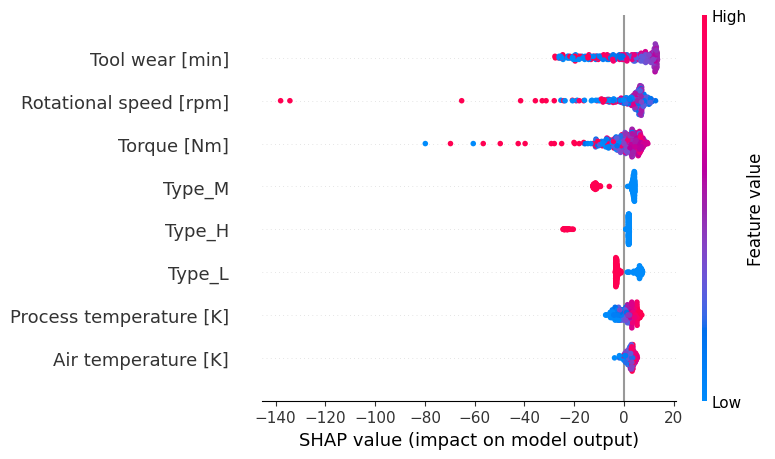

In [59]:
# Visualisasi SHAP dengan beeswarm
shap.summary_plot(shap_values, X_sample,
                  feature_names=fitur_lengkap)

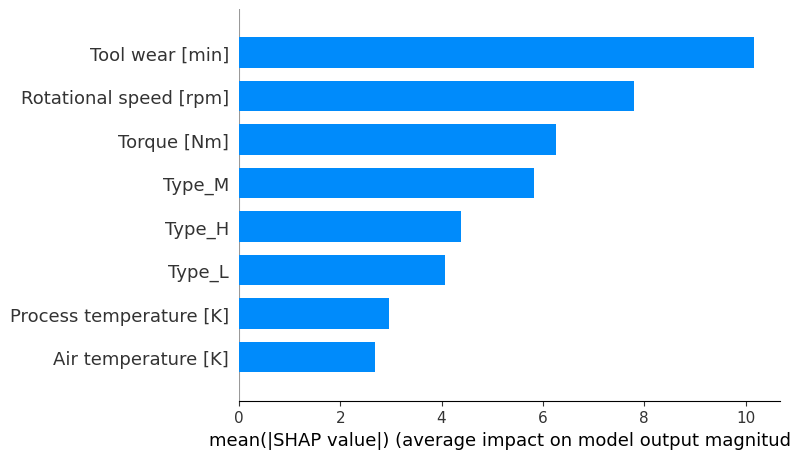

In [60]:
# KOntribusi tiap fitur menggunakan metode SHAP
shap.summary_plot(shap_values, X_sample,
                  feature_names=fitur_lengkap,
                  plot_type="bar")

Ini menghitung rata-rata dari nilai absolut SHAP value.

Artinya: Grafik ini menjawab pertanyaan, "Secara rata-rata, seberapa kuat fitur ini mengubah skor prediksi model?

# Penetapan Batas Ambang Batas

In [61]:
# menentukan skor anomali
S = model_ocsvm.decision_function(X_all_scaled)   # skor > 0 = normal, < 0 = anomali

In [62]:
df['S'] = S
score_col = 'S'

In [63]:
# Hitung Tcrit (Critical Threshold)
critical_pct = 338 / 10000
Tcrit = df[score_col].quantile(critical_pct) # Persentil RENDAH (anomali)

# Hitung T_warn menggunakan Statistik Data Normal dengan filter data yang dianggap "Normal" (Skor > 0)
df_normal = df[df[score_col] > 0]
mu_normal = df_normal[score_col].mean()
sigma_normal = df_normal[score_col].std()

# menghitung T_warn: Mu Normal - k * Sigma Normal
k_multiplier = 2.0  # <-- Sesuaikan nilai ini untuk mengubah lebar Warning zone
Twarn = mu_normal - k_multiplier * sigma_normal

print(f"Ambangan Critical (Tcrit): {Tcrit:.4f}")
print(f"Ambangan Warning (Twarn): {Twarn:.4f}")

Ambangan Critical (Tcrit): -38.7490
Ambangan Warning (Twarn): -0.6727


# Diagnosis Global (Real-Time Global Detection)

In [64]:
# Tetapkan Diagnosis Global
# Kriteria: Skor <= Tcrit = Critical, Skor > Tcrit TAPI <= Twarn = Warning
conditions = [
    df[score_col] <= Tcrit,
    df[score_col] <= Twarn
]
choices = ['Critical', 'Warning']

df['Diagnosis_Global'] = np.select(conditions, choices, default='Normal')
print("\nHasil Klasifikasi Global:")
print(df['Diagnosis_Global'].value_counts())


Hasil Klasifikasi Global:
Diagnosis_Global
Normal      8393
Warning     1269
Critical     338
Name: count, dtype: int64


# Diagnosis Lokal (Root Cause Analysis)

In [65]:
# --- DIAGNOSIS LOKAL (ROOT CAUSE ANALYSIS) ---
# Menggunakan SHAP untuk mendeteksi penyebab pada status Critical DAN Warning

# 1. Ambil index data yang statusnya Critical ATAU Warning
#    Kita butuh diagnosa untuk kedua status ini agar tidak ada "Unknown" di dashboard
anomaly_indices = df[df['Diagnosis_Global'].isin(['Critical', 'Warning'])].index

if len(anomaly_indices) > 0:
    # 2. Ambil data scaler-nya
    X_anomaly = X_all_scaled.loc[anomaly_indices]

    print(f"Sedang menghitung SHAP Values untuk {len(X_anomaly)} data (Critical + Warning)...")
    print("Mohon tunggu, proses ini mungkin memakan waktu bergantung jumlah data...")

    # 3. Hitung SHAP Values
    shap_values_anomaly = explainer.shap_values(X_anomaly)

    # Handle jika output SHAP berupa list (tergantung versi library/model)
    if isinstance(shap_values_anomaly, list):
        shap_values_anomaly = shap_values_anomaly[0]

    # Buat DataFrame sementara untuk SHAP values
    shap_df_anomaly = pd.DataFrame(shap_values_anomaly, columns=fitur_lengkap, index=anomaly_indices)

    print("\n--- Hasil Diagnosis Penyebab (SHAP-Based) ---")

    # 4. Loop setiap fitur untuk menentukan apakah dia penyebabnya
    for feature in fitur_lengkap:
        # Bersihkan nama kolom agar rapi di CSV (hapus spasi dan unit)
        clean_name = feature.replace(" ", "_").replace("[K]", "").replace("[rpm]", "").replace("[Nm]", "").replace("[min]", "")
        col_name = f'SHAP_Cause_{clean_name}'

        # Reset kolom menjadi 0 dulu untuk semua baris
        df[col_name] = 0

        # Logika: Jika nilai SHAP negatif (< 0), berarti fitur ini berkontribusi menurunkan skor (penyebab anomali)
        # Kita hanya update baris yang ada di anomaly_indices
        is_cause = shap_df_anomaly[feature] < 0 
        
        # Simpan nilai 1 (True) ke main dataframe
        df.loc[is_cause.index[is_cause], col_name] = 1
        
        # Hitung statistik
        count_cause = df[col_name].sum()
        pct_cause = (count_cause / len(anomaly_indices)) * 100
        print(f"- {col_name:35} : Penyebab pada {count_cause} kasus ({pct_cause:.1f}%)")

else:
    print("Tidak ada data Critical atau Warning yang ditemukan. SHAP dilewati.")

Sedang menghitung SHAP Values untuk 1607 data (Critical + Warning)...
Mohon tunggu, proses ini mungkin memakan waktu bergantung jumlah data...


100%|██████████| 1607/1607 [2:42:14<00:00,  6.06s/it]      


--- Hasil Diagnosis Penyebab (SHAP-Based) ---
- SHAP_Cause_Air_temperature_         : Penyebab pada 1142 kasus (71.1%)
- SHAP_Cause_Process_temperature_     : Penyebab pada 939 kasus (58.4%)
- SHAP_Cause_Rotational_speed_        : Penyebab pada 931 kasus (57.9%)
- SHAP_Cause_Torque_                  : Penyebab pada 1217 kasus (75.7%)
- SHAP_Cause_Tool_wear_               : Penyebab pada 1084 kasus (67.5%)
- SHAP_Cause_Type_H                   : Penyebab pada 306 kasus (19.0%)
- SHAP_Cause_Type_L                   : Penyebab pada 764 kasus (47.5%)
- SHAP_Cause_Type_M                   : Penyebab pada 537 kasus (33.4%)


Berbeda dengan grafik tadi, Ini menghitung jumlah data (count) di mana fitur tersebut dianggap berkontribusi (biasanya berdasarkan ambang batas tertentu atau menjadi kontributor positif).

Artinya: Teks ini menjawab pertanyaan, "Seberapa sering fitur ini muncul sebagai masalah?"

# Hasil Klasifikasi

In [66]:
cols_view = ['Product ID', 'Air temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'S', 'Diagnosis_Global']

print("\nDATA HASIL KLASIFIKASI PADA DIAGNOSIS GLOBAL")

# Fungsi helper agar coding lebih rapi saat print
def print_table(data_frame, title):
    print(f"\n[{title}]")
    print(data_frame[cols_view].head(5).to_markdown(index=False, numalign="left", stralign="left"))

print_table(df[df['Diagnosis_Global'] == 'Critical'], "5 Data Critical")
print_table(df[df['Diagnosis_Global'] == 'Warning'], "5 Data Warning")
print_table(df[df['Diagnosis_Global'] == 'Normal'], "5 Data Normal")


DATA HASIL KLASIFIKASI PADA DIAGNOSIS GLOBAL

[5 Data Critical]
| Product ID   | Air temperature [K]   | Rotational speed [rpm]   | Torque [Nm]   | S        | Diagnosis_Global   |
|:-------------|:----------------------|:-------------------------|:--------------|:---------|:-------------------|
| L47230       | 298.9                 | 2861                     | 4.6           | -187.071 | Critical           |
| L47249       | 298.9                 | 1410                     | 65.7          | -41.0004 | Critical           |
| H29569       | 298.4                 | 1987                     | 19.8          | -55.8056 | Critical           |
| L47340       | 298.4                 | 1282                     | 60.7          | -43.8579 | Critical           |
| M15054       | 298.2                 | 2678                     | 10.7          | -178.172 | Critical           |

[5 Data Warning]
| Product ID   | Air temperature [K]   | Rotational speed [rpm]   | Torque [Nm]   | S         | Diagnosis

In [67]:
# BREAKDOWN STATUS PER FITUR (FIXED)
print("\n--- 7. Breakdown Status Per Fitur (Critical/Warning/Normal) ---")

# 1. Ambil Sampel Data untuk Dianalisis
# Mengambil 5 sampel dari masing-masing kategori
idx_critical = df[df['Diagnosis_Global'] == 'Critical'].head(5).index
idx_warning  = df[df['Diagnosis_Global'] == 'Warning'].head(5).index
idx_normal   = df[df['Diagnosis_Global'] == 'Normal'].head(5).index

# Gabungkan semua indeks
target_indices = idx_critical.union(idx_warning).union(idx_normal)
X_target = X_all_scaled.loc[target_indices]

# 2. Hitung SHAP Values
print(f"Menghitung breakdown untuk {len(target_indices)} mesin terpilih...")
shap_values_target = explainer.shap_values(X_target)

# [FIX] Handle jika output SHAP berupa list (tergantung versi library)
if isinstance(shap_values_target, list):
    shap_values_target = shap_values_target[0]

# 3. Fungsi Logika Status
def determine_feature_status(shap_val):
    if shap_val < -0.2:
        return 'Critical'
    elif shap_val < 0:
        return 'Warning'
    else:
        return 'Normal'

# 4. Buat Laporan (Menggunakan Enumerate agar Index Aman)
breakdown_data = []

# Kita loop berdasarkan urutan posisi (i) dan label index aslinya (idx)
for i, idx in enumerate(target_indices):
    row_data = {}

    # Ambil Info Dasar dari DataFrame Asli menggunakan .loc[idx]
    row_data['Product ID'] = df.loc[idx, 'Product ID']
    row_data['Global_Status'] = df.loc[idx, 'Diagnosis_Global']

    # Loop setiap fitur
    for col_idx, feature in enumerate(fitur_lengkap):
        # [FIX] Ambil nilai SHAP berdasarkan posisi array [baris, kolom]
        # Ini menghindari KeyError karena tidak peduli indexnya apa
        s_val = shap_values_target[i, col_idx]

        # Tentukan status
        status = determine_feature_status(s_val)

        # Bersihkan nama kolom
        clean_name = feature.replace(" [K]", "").replace(" [rpm]", "").replace(" [Nm]", "").replace(" [min]", "")

        # Simpan
        row_data[clean_name] = status

    breakdown_data.append(row_data)

# Buat DataFrame Hasil
df_breakdown = pd.DataFrame(breakdown_data)

# 5. Tampilkan Tabel
print("\n=== TABEL DIAGNOSIS PER FITUR ===")

# Tampilkan per Fitur seperti permintaan Anda
feature_cols = ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']

for feat in feature_cols:
    print(f"\n>>> Analisis pada Fitur: {feat}")
    print("-" * 60)

    # Kita filter hanya kolom yang relevan
    cols_to_show = ['Product ID', feat, 'Global_Status']

    # Pisahkan berdasarkan status fitur tersebut
    for status in ['Critical', 'Warning', 'Normal']:
        subset = df_breakdown[df_breakdown[feat] == status]

        if not subset.empty:
            print(f"\n  [{status.upper()}]")
            # Tampilkan tabel tanpa index agar rapi
            print(subset[cols_to_show].to_markdown(index=False, tablefmt="simple"))


--- 7. Breakdown Status Per Fitur (Critical/Warning/Normal) ---
Menghitung breakdown untuk 15 mesin terpilih...


100%|██████████| 15/15 [00:21<00:00,  1.42s/it]


=== TABEL DIAGNOSIS PER FITUR ===

>>> Analisis pada Fitur: Air temperature
------------------------------------------------------------

  [CRITICAL]
Product ID    Air temperature    Global_Status
------------  -----------------  ---------------
L47230        Critical           Critical
M15054        Critical           Critical

  [NORMAL]
Product ID    Air temperature    Global_Status
------------  -----------------  ---------------
M14860        Normal             Normal
L47181        Normal             Normal
L47182        Normal             Normal
L47183        Normal             Normal
L47184        Normal             Normal
H29424        Normal             Warning
L47194        Normal             Warning
L47249        Normal             Critical
M14930        Normal             Warning
L47259        Normal             Warning
H29494        Normal             Warning
H29569        Normal             Critical
L47340        Normal             Critical

>>> Analisis pada Fitur: Pro

In [72]:
# Menampilkan tabel klasifikasi lengkap per mesin
print("\n--- MASTER TABLE: Klasifikasi Status Per Sensor ---")
# Menampilkan 10 baris pertama
print(df_breakdown.head(10).to_markdown(index=False))


--- MASTER TABLE: Klasifikasi Status Per Sensor ---
| Product ID   | Global_Status   | Air temperature   | Process temperature   | Rotational speed   | Torque           | Tool wear        | Type_H          | Type_L           | Type_M           |
|:-------------|:----------------|:------------------|:----------------------|:-------------------|:-----------------|:-----------------|:----------------|:-----------------|:-----------------|
| M14860       | Normal          | Normal            | Normal                | Normal             | Normal           | Critical (46.2%) | Normal          | Normal           | Critical (20.2%) |
| L47181       | Normal          | Normal            | Normal                | Normal             | Normal           | Critical (51.9%) | Normal          | Critical (6.2%)  | Normal           |
| L47182       | Normal          | Normal            | Normal                | Normal             | Critical (10.6%) | Critical (47.3%) | Normal          | Critical (6.0%)

In [74]:
feature_names = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']

col_map = {
    'Air temperature': 'Air temperature [K]',
    'Process temperature': 'Process temperature [K]',
    'Rotational speed': 'Rotational speed [rpm]',
    'Torque': 'Torque [Nm]',
    'Tool wear': 'Tool wear [min]',
    'Type_H': 'Type_H',
    'Type_L': 'Type_L',
    'Type_M': 'Type_M'
}

total_impact_per_row = np.sum(np.abs(shap_values), axis=1)
total_impact_per_row[total_impact_per_row == 0] = 1
for display_col, feature_col in col_map.items():
    try:
        feat_idx = feature_names.index(feature_col)
    except ValueError:
        continue # Lewati jika nama kolom tidak ditemukan

    feature_shap_vals = np.abs(shap_values[:, feat_idx])
    contribution_pcts = (feature_shap_vals / total_impact_per_row) * 100

    new_column_content = []

    for i, current_status in enumerate(df_breakdown[display_col]):
        if "Critical" in current_status:
            base_status = "Critical"
            pct = contribution_pcts[i]
            new_str = f"{base_status} ({pct:.1f}%)"
            new_column_content.append(new_str)
        else:
            new_column_content.append("Normal")

    df_breakdown[display_col] = new_column_content

print("\n--- MASTER TABLE: Diagnosis Lokal dengan SHAP Contribution % ---")
print("Angka % menunjukkan seberapa besar sensor tersebut mempengaruhi keputusan model menjadi 'Rusak'.")
print(df_breakdown.head(10).to_markdown(index=False))


--- MASTER TABLE: Diagnosis Lokal dengan SHAP Contribution % ---
Angka % menunjukkan seberapa besar sensor tersebut mempengaruhi keputusan model menjadi 'Rusak'.
| Product ID   | Global_Status   | Air temperature   | Process temperature   | Rotational speed   | Torque           | Tool wear        | Type_H          | Type_L           | Type_M           |
|:-------------|:----------------|:------------------|:----------------------|:-------------------|:-----------------|:-----------------|:----------------|:-----------------|:-----------------|
| M14860       | Normal          | Normal            | Normal                | Normal             | Normal           | Critical (46.2%) | Normal          | Normal           | Critical (20.2%) |
| L47181       | Normal          | Normal            | Normal                | Normal             | Normal           | Critical (51.9%) | Normal          | Critical (6.2%)  | Normal           |
| L47182       | Normal          | Normal            | Normal

In [75]:
import pandas as pd
import numpy as np
import re # Kita pakai regex agar cleaning nama lebih aman

export_data = []

# Hitung total impact
total_impacts = np.sum(np.abs(shap_values), axis=1)

for i in range(len(shap_values)):
    prod_id = df.iloc[i]['Product ID']
    global_stat = df.iloc[i]['Diagnosis_Global']

    # --- LOGIC 1: MENENTUKAN MAIN CAUSE ---
    # Jika mesin Normal, kita tidak butuh Main Cause yang menakutkan
    if global_stat == 'Normal':
        main_cause_sensor = "-"
        main_cause_pct = 0.0
    else:
        # Hanya hitung penyebab jika Warning/Critical
        row_shap = np.abs(shap_values[i])
        max_idx = np.argmax(row_shap)
        main_cause_sensor = feature_names[max_idx]

        if total_impacts[i] == 0:
            main_cause_pct = 0
        else:
            main_cause_pct = (row_shap[max_idx] / total_impacts[i]) * 100

    # --- LOGIC 2: DETAIL SENSOR UNTUK FILTERING ---
    sensor_details = {}
    for idx, feat in enumerate(feature_names):
        # Cleaning nama yang lebih robust (hapus unit dalam kurung siku dan spasi jadi underscore)
        # Contoh: "Air temperature [K]" -> "Air_temperature"
        clean_feat_name = re.sub(r'\s*\[.*?\]', '', feat).replace(" ", "_")

        # Coba beberapa variasi nama kolom SHAP yang mungkin ada di df kamu
        # (Karena kadang ada underscore di akhir, kadang tidak)
        possible_cols = [
            f'SHAP_Cause_{clean_feat_name}',
            f'SHAP_Cause_{clean_feat_name}_'
        ]

        # Cari mana kolom yang benar-benar eksis di df
        found_col = None
        for col in possible_cols:
            if col in df.columns:
                found_col = col
                break

        # Logic penetapan status
        if found_col and df.iloc[i][found_col] == 1:
            status_val = 'Critical'
        elif global_stat == 'Warning':
            # Fallback: Jika global Warning & bukan critical cause, set Warning
            status_val = 'Warning'
        elif global_stat == 'Critical':
             # Fallback: Jika global Critical tapi sensor ini bukan penyebab (0), dia Normal
            status_val = 'Normal'
        else:
            status_val = 'Normal'

        # Simpan dengan key nama asli (agar rapi di UI) atau nama bersih (agar mudah di query)
        # Disini saya pakai nama asli feature_names agar label di website bagus
        sensor_details[feat] = status_val

    # Susun Row Data
    row_data = {
        'Product_ID': prod_id,
        'Diagnosis_Global': global_stat,
        'Main_Cause': main_cause_sensor,
        'Confidence_Pct': round(main_cause_pct, 1),
        'Sensor_Data': sensor_details
    }

    export_data.append(row_data)

df_website = pd.DataFrame(export_data)

# Cek hasil
print(df_website.head())
print("\nCek salah satu isi Sensor_Data baris pertama:")
print(df_website.iloc[0]['Sensor_Data'])

  Product_ID Diagnosis_Global Main_Cause  Confidence_Pct  \
0     M14860           Normal          -             0.0   
1     L47181           Normal          -             0.0   
2     L47182           Normal          -             0.0   
3     L47183           Normal          -             0.0   
4     L47184           Normal          -             0.0   

                                         Sensor_Data  
0  {'Air temperature [K]': 'Normal', 'Process tem...  
1  {'Air temperature [K]': 'Normal', 'Process tem...  
2  {'Air temperature [K]': 'Normal', 'Process tem...  
3  {'Air temperature [K]': 'Normal', 'Process tem...  
4  {'Air temperature [K]': 'Normal', 'Process tem...  

Cek salah satu isi Sensor_Data baris pertama:
{'Air temperature [K]': 'Normal', 'Process temperature [K]': 'Normal', 'Rotational speed [rpm]': 'Normal', 'Torque [Nm]': 'Normal', 'Tool wear [min]': 'Normal', 'Type_H': 'Normal', 'Type_L': 'Normal', 'Type_M': 'Normal'}


In [76]:
import joblib
import json

joblib.dump(model_ocsvm, 'model_ocsvm.pkl')
joblib.dump(scaler, 'scaler.pkl')

# 3. Simpan Threshold (Tcrit & Twarn) agar backend tidak perlu hitung ulang
thresholds = {
    'Tcrit': Tcrit,
    'Twarn': Twarn
}
# Simpan sebagai JSON agar mudah dibaca manusia (opsional, bisa juga pkl)
with open('thresholds.json', 'w') as f:
    json.dump(thresholds, f)
joblib.dump(background, 'shap_background.pkl')

df.to_csv('data_hasil_model.csv', index=False)
print("✅ Semua file berhasil disimpan: model_ocsvm.pkl, scaler.pkl, thresholds.json, shap_background.pkl, 'data_hasil_model.csv'")

✅ Semua file berhasil disimpan: model_ocsvm.pkl, scaler.pkl, thresholds.json, shap_background.pkl, 'data_hasil_model.csv'
